In [ ]:
# !pip install polars
# !pip install pyarrow

In [1]:
from pathlib import Path
import polars as pl
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import IncrementalPCA
from sklearn.preprocessing import StandardScaler
import gc

pd.set_option('display.float_format', lambda x: f'{x:.4f}')

In [7]:
data_base_dir = Path('data/regionwise_yearwise_samples')
TARGET_REGION = 'WGR'
REGION_DIR = data_base_dir / TARGET_REGION

# Lazy scan pattern: scans all year partitions without loading them into RAM
lazy_dataset = pl.scan_parquet(REGION_DIR / "**/*.parquet")

# Load legend definitions
legends_df = pd.read_csv('data/class_legend.csv')
class_name_map = dict(zip(legends_df['class_code'], legends_df['class_name']))

# Get list of years present across the partitions
years_present = (
    lazy_dataset.select('year')
    .unique()
    .collect()
    .sort('year')['year']
    .to_list()
)
print(f"Target Region: {TARGET_REGION}")
print(f"Years discovered ({len(years_present)}): {years_present[:4]} ... {years_present[-4:]}")

Target Region: WGR
Years discovered (39): [1987, 1988, 1989, 1990] ... [2022, 2023, 2024, 2025]


In [8]:
with pd.option_context("display.max_columns", None):
    display(lazy_dataset.limit(5).collect().to_pandas())

,system:index,BareEarth,StableWater,area_m2,area_proportion,aspect_cos,aspect_sin,bci_mad,bci_median,blue_mad,blue_median,blue_median_dry,blue_median_wet,blue_swing,class,elevation,evi2_mad,evi2_median,evi2_median_dry,evi2_median_wet,evi2_swing,green_mad,green_median,green_median_dry,green_median_wet,green_swing,gv_mad,gv_median,gv_median_dry,gv_median_wet,gv_swing,hand,ibi_mad,ibi_median,lat,lon,mndwi_mad,mndwi_median,mndwi_median_dry,mndwi_median_wet,mndwi_swing,mosaic_version,ndfi_mad,ndfi_median,ndfi_median_dry,ndfi_median_wet,ndfi_swing,ndmi_mad,ndmi_median,ndmi_median_dry,ndmi_median_wet,ndmi_swing,ndvi_mad,ndvi_median,ndvi_median_dry,ndvi_median_wet,ndvi_p25,ndvi_p75,ndvi_q1_median,ndvi_q2_median,ndvi_q3_median,ndvi_q4_median,ndvi_swing,nir_mad,nir_median,nir_median_dry,nir_median_wet,nir_swing,npv_mad,npv_median,npv_median_dry,npv_median_wet,npv_swing,q1_count,q2_count,q3_count,q4_count,quarters_present,red_mad,red_median,red_median_dry,red_median_wet,red_swing,shade_mad,shade_median,shade_median_dry,shade_median_wet,shade_swing,slope,snow_count,soil_mad,soil_median,soil_median_dry,soil_median_wet,soil_swing,swir1_mad,swir1_median,swir1_median_dry,swir1_median_wet,swir1_swing,swir2_mad,swir2_median,swir2_median_dry,swir2_median_wet,swir2_swing,tcb_mad,tcb_median,tcb_median_dry,tcb_median_wet,tcb_swing,tcg_mad,tcg_median,tcg_median_dry,tcg_median_wet,tcg_swing,tcw_mad,tcw_median,tcw_median_dry,tcw_median_wet,tcw_swing,tir_count,tir_mad,tir_median,usable_count,year,.geo
0,0000000000000000c5ab,25,NaN,13541.4541,0.1428,-2603,3718,4,88,196,558,754,362,-393,25,565,208,2160,1952,2368,416,108,845,953,737,-216,1,14,15,13,-2,1830,9,100,99140,773647,1602,-3732,-2129,-5334,-3205,2,39,148,186,108,-78,1037,759,1797,-278,-2074,313,3963,3650,4276,3650,4276,NaN,NaN,3650,4276,626,90,2203,2113,2292,179,2,1,3,0,-3,NaN,NaN,1,1,2,32,951,983,919,-64,10,69,79,59,-20,2700,0,13,15,3,28,25,477,1946,1469,2423,954,449,1442,994,1891,897,174,2748,2574,2923,349,45,729,774,685,-90,597,-2055,-1457,-2652,-1194,1,0,3057,2,1987,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,0000000000000000c5ac,25,NaN,13541.4541,0.1428,-3971,2780,0,105,445,709,1154,265,-889,25,604,176,1402,1226,1578,352,376,972,1348,596,-752,1,9,9,8,-1,2000,7,100,99143,773642,1542,-2827,-1285,-4368,-3084,2,25,162,181,132,-49,646,602,1248,-44,-1291,855,2939,2083,3794,2083,3794,NaN,NaN,2083,3794,1711,368,1875,2243,1507,-735,4,3,6,0,-6,NaN,NaN,1,1,2,396,1074,1469,678,-791,4,81,85,76,-9,2900,0,9,8,0,17,17,112,1633,1745,1521,-224,23,1219,1196,1242,46,587,2600,3187,2013,-1174,61,460,521,399,-122,0,-1646,-1646,-1646,0,1,0,3045,2,1987,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,0000000000000000c5ad,25,NaN,13541.4541,0.1428,-4180,4329,1,103,244,529,774,285,-489,25,592,107,1533,1426,1641,215,156,770,925,614,-311,2,8,10,7,-4,1990,8,104,99143,773644,1333,-3755,-2422,-5088,-2666,2,42,141,176,92,-84,841,209,1050,-632,-1683,417,3224,2807,3641,2807,3641,NaN,NaN,2807,3641,835,106,1768,1873,1662,-211,3,1,4,0,-4,NaN,NaN,1,1,2,139,913,1052,775,-277,6,77,82,69,-13,3700,0,11,14,3,25,21,185,1702,1517,1886,369,302,1318,1016,1620,603,79,2401,2479,2322,-158,95,449,544,354,-190,296,-1789,-1493,-2084,-591,1,0,3051,2,1987,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,0000000000000000c5ae,25,NaN,13541.4541,0.1428,-3262,4175,3,97,188,595,783,406,-376,25,576,204,1596,1392,1801,409,115,867,982,752,-231,2,10,12,8,-3,1910,10,103,99143,773647,1637,-3639,-2002,-5277,-3275,2,49,139,187,88,-99,1099,403,1501,-696,-2197,362,2965,2603,3327,2603,3327,NaN,NaN,2603,3327,724,60,2055,1995,2114,119,2,2,4,0,-4,NaN,NaN,1,1,2,56,1115,1171,1059,-112,10,73,83,63,-20,3200,0,14,15,1,29,28,478,1953,1474,2431,956,502,1464,962,1966,1004,163,2779,2616,2943,326,74,529,604,455,-149,616,-2036,-1420,-2652,-1232,1,0,3051,2,1987,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,0000000000000000c5af,25,NaN,13541.4541,0.1428,-2182,544,5,99,747,1036,1782,289,-1494,25,611,425,1480,1054,1905,851,559,1200,1758,641,-1117,2,10,9,12,4,1840,6,99,99145,7

In [9]:
# ==============================================================================
# Pixel-Quality Gate Configuration (mirrors GEE Step_05b / stable map script)
# ==============================================================================
MIN_USABLE_LOOKS = 5    # Minimum clear looks in a phenological year
MIN_QUARTERS = 3        # Minimum quarters observed out of 4 (q1..q4)
# MIN_GOOD_YEARS = 5      # Believable years needed before calling a pixel stable

# Define the predicate for believing a single year's observation at a pixel
pixel_quality_condition = (
    (pl.col("usable_count") >= MIN_USABLE_LOOKS) &
    (pl.col("quarters_present") >= MIN_QUARTERS)
)

# Apply the gate to create a filtered lazy scan
lazy_dataset_gated = lazy_dataset.filter(pixel_quality_condition)

In [10]:
total_rows = lazy_dataset.select(pl.len()).collect().item()
total_cols = len(lazy_dataset.collect_schema().names())
print(f"Total dataset shape across all years: ({total_rows:,}, {total_cols})")

Total dataset shape across all years: (2,334,287, 126)


In [11]:
lazy_dataset.collect_schema().names()

['system:index',
 'BareEarth',
 'StableWater',
 'area_m2',
 'area_proportion',
 'aspect_cos',
 'aspect_sin',
 'bci_mad',
 'bci_median',
 'blue_mad',
 'blue_median',
 'blue_median_dry',
 'blue_median_wet',
 'blue_swing',
 'class',
 'elevation',
 'evi2_mad',
 'evi2_median',
 'evi2_median_dry',
 'evi2_median_wet',
 'evi2_swing',
 'green_mad',
 'green_median',
 'green_median_dry',
 'green_median_wet',
 'green_swing',
 'gv_mad',
 'gv_median',
 'gv_median_dry',
 'gv_median_wet',
 'gv_swing',
 'hand',
 'ibi_mad',
 'ibi_median',
 'lat',
 'lon',
 'mndwi_mad',
 'mndwi_median',
 'mndwi_median_dry',
 'mndwi_median_wet',
 'mndwi_swing',
 'mosaic_version',
 'ndfi_mad',
 'ndfi_median',
 'ndfi_median_dry',
 'ndfi_median_wet',
 'ndfi_swing',
 'ndmi_mad',
 'ndmi_median',
 'ndmi_median_dry',
 'ndmi_median_wet',
 'ndmi_swing',
 'ndvi_mad',
 'ndvi_median',
 'ndvi_median_dry',
 'ndvi_median_wet',
 'ndvi_p25',
 'ndvi_p75',
 'ndvi_q1_median',
 'ndvi_q2_median',
 'ndvi_q3_median',
 'ndvi_q4_median',
 'ndvi_swi

In [9]:
# ------------------------------------------------------------------------------
# Diagnostic: Assess data loss per year and per class from the quality gate
# ------------------------------------------------------------------------------
retention_stats = (
    lazy_dataset.select([
        "year",
        "class",
        pixel_quality_condition.alias("is_believed")
    ])
    .group_by(["year", "class"])
    .agg([
        pl.len().alias("total_samples"),
        pl.col("is_believed").sum().alias("passed_samples"),
        (~pl.col("is_believed")).sum().alias("dropped_samples"),
        ((pl.col("is_believed").sum() / pl.len()) * 100).round(2).alias("pass_percentage")
    ])
    .collect()
    .sort(["year", "class"])
)

# Overall retention rate across the entire bio-geographic region
total_raw = retention_stats["total_samples"].sum()
total_passed = retention_stats["passed_samples"].sum()
print(f"Overall Retained: {total_passed:,} / {total_raw:,} ({total_passed / total_raw * 100:.2f}%)")

# Inspect years or classes with highest drop rates
print("\nTop 10 year-class buckets with highest drop rates (< 70% retention):")
display(retention_stats.filter(pl.col("pass_percentage") < 70.0).to_pandas())

Overall Retained: 4,269,198 / 4,501,107 (94.85%)

Top 10 year-class buckets with highest drop rates (< 70% retention):


,year,class,total_samples,passed_samples,dropped_samples,pass_percentage
0,1987,4,7144,0,7144,0.0000
1,1987,5,5080,0,5080,0.0000
2,1987,9,311,0,311,0.0000
3,1987,11,4536,0,4536,0.0000
4,1987,12,7922,0,7922,0.0000
5,1987,19,11715,0,11715,0.0000
6,1987,23,155,0,155,0.0000
7,1987,24,5994,0,5994,0.0000
8,1987,25,5592,0,5592,0.0000
9,1987,30,5425,0,5425,0.0000


In [16]:
# Compute null counts across the entire dataset out-of-core
null_counts = lazy_dataset_gated.null_count().collect()

# Pivot vertically and filter to columns with missing data
null_summary = (
    null_counts.unpivot(variable_name="column", value_name="null_count")
    .filter(pl.col("null_count") > 0)
    .sort("null_count", descending=True)
)

print("Columns with missing values (shown vertically):")
with pl.Config(tbl_rows=-1):
    print(null_summary)

Columns with missing values (shown vertically):
shape: (11, 2)
┌────────────────┬────────────┐
│ column         ┆ null_count │
│ ---            ┆ ---        │
│ str            ┆ u32        │
╞════════════════╪════════════╡
│ ndvi_q2_median ┆ 698458     │
│ q2_count       ┆ 698458     │
│ ndvi_q1_median ┆ 623465     │
│ q1_count       ┆ 623465     │
│ ndvi_q4_median ┆ 180342     │
│ q4_count       ┆ 180342     │
│ ndvi_q3_median ┆ 120664     │
│ q3_count       ┆ 120664     │
│ tir_count      ┆ 449        │
│ tir_mad        ┆ 449        │
│ tir_median     ┆ 449        │
└────────────────┴────────────┘


In [25]:
# # 1. Take a 1,000-point sample across the dataset (or filter to a single year: .filter(pl.col('year') == 2024))
# sample_pdf = (
#     lazy_dataset_gated
#     .select(['lat', 'lon', 'class', 'year', 'elevation'])
#     .collect()
#     .sample(n=1000, seed=42)
#     .to_pandas()
# )

# # 2. Rescale coordinates only on the 1,000 rows
# sample_gdf = gpd.GeoDataFrame(
#     sample_pdf,
#     geometry=gpd.points_from_xy(sample_pdf['lon'] / 10000, sample_pdf['lat'] / 10000),
#     crs="EPSG:4326"
# )

# # 3. Interactive map preview
# sample_gdf.explore(column='class', cmap='tab20', legend=True)

In [18]:
# Example: Inspect class counts for benchmark year 2024
benchmark_year = 2024

class_dist_2024 = (
    lazy_dataset_gated
    .filter(pl.col('year') == benchmark_year)
    .group_by('class')
    .agg(pl.len().alias('count'))
    .sort('count', descending=True)
    .collect()
    .with_columns(
        pl.col('class').map_elements(lambda c: class_name_map.get(c, 'Unknown'), return_dtype=pl.String).alias('class_name')
    )
)

print(f"Class Distribution for Year {benchmark_year}:")
print(class_dist_2024)

Class Distribution for Year 2024:
shape: (16, 3)
┌───────┬───────┬───────────────────────────┐
│ class ┆ count ┆ class_name                │
│ ---   ┆ ---   ┆ ---                       │
│ i64   ┆ u32   ┆ str                       │
╞═══════╪═══════╪═══════════════════════════╡
│ 33    ┆ 19971 ┆ StableWater               │
│ 19    ┆ 16553 ┆ Open Seasonal Agriculture │
│ 4     ┆ 11842 ┆ DeciduousForest           │
│ 24    ┆ 10931 ┆ BuiltUp                   │
│ 76    ┆ 10543 ┆ TransientWater            │
│ …     ┆ …     ┆ …                         │
│ 61    ┆ 4971  ┆ SaltPans                  │
│ 75    ┆ 3043  ┆ SandDunes                 │
│ 36    ┆ 698   ┆ AgroForestry              │
│ 9     ┆ 334   ┆ ForestPlantation          │
│ 23    ┆ 155   ┆ Beaches                   │
└───────┴───────┴───────────────────────────┘


In [ ]:
cols_to_drop = [
    'class', 'system:index', 'area_m2', 'area_proportion', 'usable_count',
    '.geo', 'q1_count', 'q2_count', 'q3_count', 'q4_count', 'quarters_present',
    'geometry', 'ndvi_q1_median', 'ndvi_q2_median', 'ndvi_q3_median',
    'ndvi_q4_median', 'tir_count', 'tir_mad', 'tir_median', 'snow_count', 'year',
    'mosaic_version','BareEarth', 'StableWater','TransientWater'
]

schema = lazy_dataset_gated.collect_schema()
feature_cols = [c for c in schema.names() if c not in cols_to_drop]

# Sample 50,000 rows across benchmark years for PCA visualization
pca_sample_size = 50000
df_sample = (
    lazy_dataset_gated
    .select(feature_cols + ['class'])
    .collect()
    .sample(n=pca_sample_size, seed=42)
)

X_sample = df_sample.select(feature_cols).to_numpy().astype(np.float32)
y_sample = df_sample['class'].to_numpy().ravel()

print(f"X sample shape: {X_sample.shape}, y sample shape: {y_sample.shape}")

X sample shape: (50000, 104), y sample shape: (50000,)


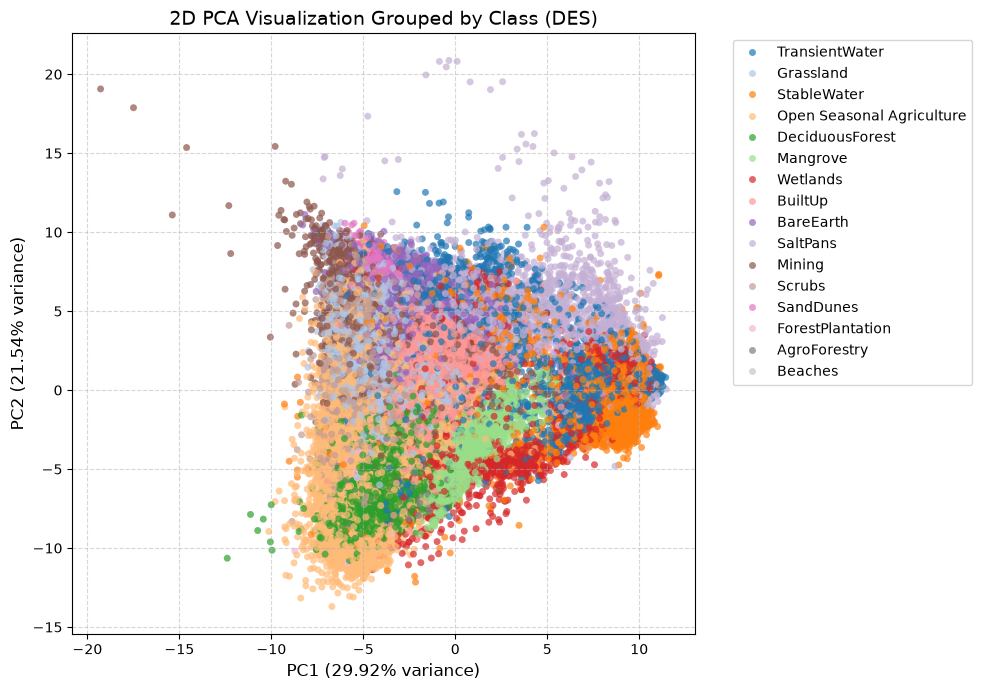

In [21]:
# 1. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

# 2. PCA projection to 2 components
pca = IncrementalPCA(n_components=2, batch_size=10000)
pca_features = pca.fit_transform(X_scaled)

# 3. Build plot dataframe with labels
pca_df = pd.DataFrame(data=pca_features, columns=["PC1", "PC2"])
pca_df["Class"] = y_sample
pca_df["Class"] = pca_df["Class"].map(class_name_map)

# 4. Scatter plot
plt.figure(figsize=(10, 7))
palette = sns.color_palette("tab20", len(pca_df["Class"].dropna().unique()))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Class",
    palette=palette,
    s=25,
    alpha=0.7,
    edgecolor="none"
)
plt.title(f"2D PCA Visualization Grouped by Class ({TARGET_REGION})", fontsize=14)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)", fontsize=12)
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0.5)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Check correlation in features

In [ ]:
# correlation_matrix = X.corr(method='pearson')

In [30]:
corr_sample_size = min(200000, lazy_dataset_gated.collect().shape[0])
# Sample 50,000 rows across benchmark years for PCA visualization
df_sample = (
    lazy_dataset_gated
    .select(feature_cols + ['class'])
    .collect()
    .sample(n=corr_sample_size, seed=42)
)

X_corr_sample = df_sample.select(feature_cols).to_numpy().astype(np.float32)

y_corr_sample = df_sample.select('class').to_numpy().ravel()

print(f"X sample shape: {X_corr_sample.shape}, y sample shape: {y_corr_sample.shape}")

X sample shape: (200000, 104), y sample shape: (200000,)


In [31]:
# Compute feature correlation matrix via NumPy
corr_matrix = np.abs(np.corrcoef(X_corr_sample, rowvar=False))
corr_df = pd.DataFrame(corr_matrix, index=feature_cols, columns=feature_cols)

# Compute Pearson correlation with target y
y_norm = (y_corr_sample - np.mean(y_corr_sample)) / np.std(y_corr_sample)
X_norm = (X_corr_sample - np.mean(X_corr_sample, axis=0)) / np.std(X_corr_sample, axis=0)
target_corr = np.abs(np.mean(X_norm * y_norm[:, np.newaxis], axis=0))
target_corr_series = pd.Series(target_corr, index=feature_cols)

# Multicollinearity filtering (threshold = 0.8)
threshold = 0.8
upper = corr_df.where(np.triu(np.ones(corr_df.shape), k=1).astype(bool))

to_drop = set()
for col in upper.columns:
    correlated_features = upper.index[upper[col] > threshold].tolist()
    for feat in correlated_features:
        if target_corr_series[feat] < target_corr_series[col]:
            to_drop.add(feat)
        else:
            to_drop.add(col)

print(f"Features identified to drop: {len(to_drop)}")
print(f"Features retained: {len(feature_cols) - len(to_drop)}")

/home/nirzaree/Code/GitClones/IOLN/.IOLN/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/nirzaree/Code/GitClones/IOLN/.IOLN/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/tmp/ipykernel_32099/3358441697.py:7: RuntimeWarning: invalid value encountered in divide
  X_norm = (X_corr_sample - np.mean(X_corr_sample, axis=0)) / np.std(X_corr_sample, axis=0)


Features identified to drop: 67
Features retained: 37
